# Hydrogen recombination and CMB photon decoupling

This notebook walks through the physics implemented in the `cmb_decoupling` package, from Saha
equilibrium to the Peebles three-level atom, and on to the optical depth and visibility function
that define the last-scattering surface. Each step is compared with CAMB (RECFAST recombination).
Full derivations are in [`docs/theory.md`](../docs/theory.md).

**Cosmology.** Planck 2018 VI, Table 2, TT,TE,EE+lowE+lensing, with massless neutrinos
(N_eff = 3.046), defined once in `cmb_decoupling.cosmology.PLANCK2018`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cmb_decoupling import (
    PLANCK2018,
    decoupling_redshift,
    last_scattering,
    saha_redshift,
    solve_peebles,
    thomson_rate,
    x_e_saha_full,
    x_e_saha_hydrogen,
)
from cmb_decoupling.peebles import RECFAST_FUDGE, peebles_C
from cmb_decoupling.plotting import STYLES, use_style
from cmb_decoupling.reference import camb_reference
from cmb_decoupling.results import key_results

use_style()
cosmo = PLANCK2018
print(f"H0 = {cosmo.H0_km_s_Mpc} km/s/Mpc, Omega_b h^2 = {cosmo.omega_b}, Omega_m = {cosmo.Omega_m:.4f}")
print(f"Omega_r = {cosmo.Omega_r:.4e}, Y_p = {cosmo.Y_p}, n_H0 = {cosmo.n_H0:.4f} m^-3")


def saha_xe(zz):
    # Saha x_e including helium, for the Planck 2018 cosmology.
    return x_e_saha_full(zz, cosmo)

H0 = 67.36 km/s/Mpc, Omega_b h^2 = 0.02237, Omega_m = 0.3138
Omega_r = 9.2205e-05, Y_p = 0.2454, n_H0 = 0.1895 m^-3


## 1. Saha equilibrium

If ionisation and recombination are fast compared with the expansion, the populations follow the
Saha equation. For pure hydrogen with $x_e = n_e/n_{\rm H}$,

$$\frac{x_e^2}{1-x_e} = \frac{1}{n_{\rm H}}\left(\frac{m_e k_B T}{2\pi\hbar^2}\right)^{3/2} e^{-E_{\rm ion}/k_B T}.$$

Because there are about $10^9$ photons per baryon, hydrogen stays ionised until $k_BT \approx E_{\rm ion}/40$,
far below $E_{\rm ion} = 13.6$ eV.

Saha (H only): x_e = 0.5 at z = 1369.0


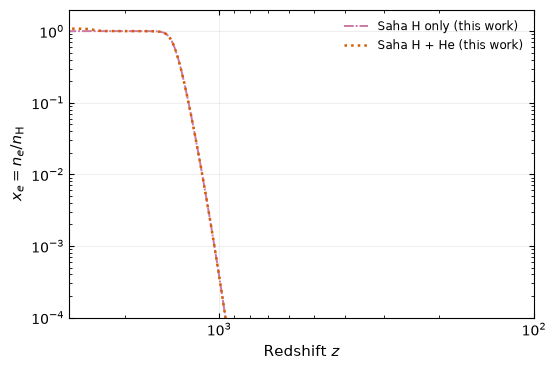

In [2]:
z = np.geomspace(100, 3000, 1500)
print(f"Saha (H only): x_e = 0.5 at z = {saha_redshift(cosmo):.1f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(z, x_e_saha_hydrogen(z, cosmo), **STYLES["saha_h"])
ax.plot(z, x_e_saha_full(z, cosmo), **STYLES["saha_full"])
ax.set(xscale="log", yscale="log", ylim=(1e-4, 2), xlim=(3000, 100),
       xlabel="Redshift $z$", ylabel="$x_e = n_e/n_{\\rm H}$")
ax.legend();

Including helium (Saha for He I ↔ He II ↔ He III) raises $x_e$ above 1 at $z \gtrsim 2000$, because
each helium nucleus contributes up to two electrons.

**Why Saha fails.** Recombination directly to the ground state emits a photon that immediately ionises
another atom, and each Lyman-α photon from a 2p→1s decay is resonantly re-absorbed. The gas cannot reach
the ground state as fast as equilibrium requires, so the real $x_e$ lags behind Saha. Saha also predicts
that $x_e$ falls exponentially to zero, while in reality the recombination rate drops below the expansion
rate and $x_e$ *freezes out*.

## 2. The Peebles three-level atom

Peebles (1968) follows the net recombination rate through the $n=2$ level:

$$\frac{dx_e}{dz} = \frac{C_r}{H(z)(1+z)}\Big[\alpha_B n_{\rm H} x_e^2 - \beta_B (1-x_e) e^{-E_{{\rm Ly}\alpha}/k_BT}\Big],
\qquad
C_r = \frac{\Lambda_{2s1s} + \Lambda_\alpha}{\Lambda_{2s1s} + \Lambda_\alpha + \beta_B},$$

with $\Lambda_\alpha = 8\pi H/(\lambda_{{\rm Ly}\alpha}^3 n_{1s})$ the rate at which Lyman-α photons redshift out
of the line, and $\Lambda_{2s1s} = 8.22\ {\rm s}^{-1}$ the two-photon decay rate. $C_r$ is the probability that an
atom in $n=2$ reaches the ground state before being photo-ionised. The ODE is stiff, so it is
integrated with an implicit Radau method from Saha equilibrium at $z = 1800$.

CAMB recombination model: Recfast


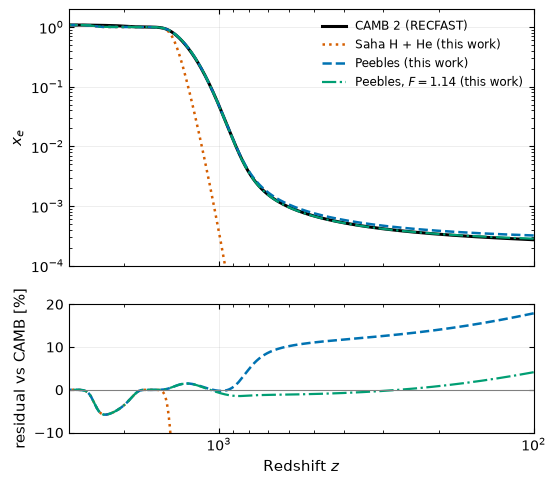

In [3]:
peebles = solve_peebles(cosmo)
peebles_fudge = solve_peebles(cosmo, fudge=RECFAST_FUDGE)
ref = camb_reference(cosmo)
print("CAMB recombination model:", ref.recombination_model)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(6, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for key, f in [("camb", ref.x_e), ("saha_full", saha_xe),
               ("peebles", peebles.x_e), ("peebles_fudge", peebles_fudge.x_e)]:
    ax.plot(z, f(z), **STYLES[key])
    if key != "camb":
        axr.plot(z, 100 * (f(z) / ref.x_e(z) - 1), **{k: v for k, v in STYLES[key].items() if k != "label"})
ax.set(xscale="log", yscale="log", ylim=(1e-4, 2), ylabel="$x_e$")
ax.legend()
axr.axhline(0, color="grey", lw=0.8)
axr.set(xlim=(3000, 100), ylim=(-10, 20), xlabel="Redshift $z$", ylabel="residual vs CAMB [%]");

The Peebles model follows CAMB to within about 2% through the epoch that sets last scattering
($1000 \lesssim z \lesssim 1500$). Two differences remain:

* **$z \approx 1800$–$2800$:** helium is in Saha equilibrium here, while RECFAST delays He I recombination.
* **$z \lesssim 900$:** the three-level atom over-predicts the residual ionisation by 10–18%. The RECFAST
  fudge factor $F = 1.14$ (Seager et al. 1999), which mimics the multi-level atom, removes most of this.
  The rest comes from assuming $T_{\rm m} = T_\gamma$; the real gas cools faster at late times.

The factor $C_r$ shows why recombination is slow: near $z \approx 1100$ only a few per cent of the atoms
that reach $n=2$ go on to the ground state.

C_r at z = 1100: 0.0218


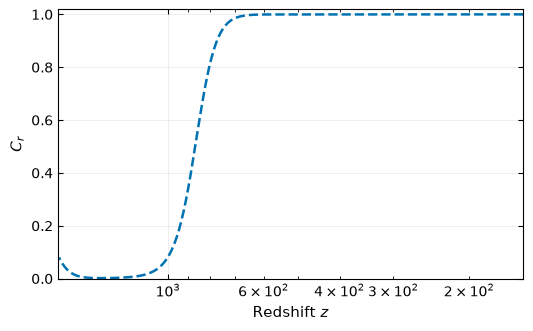

In [4]:
zc = np.geomspace(150, 1790, 400)
C = [peebles_C(zi, float(peebles.x_e(zi)), cosmo) for zi in zc]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(zc, C, **{k: v for k, v in STYLES["peebles"].items() if k != "label"})
ax.set(xscale="log", xlim=(1800, 150), ylim=(0, 1.02), xlabel="Redshift $z$", ylabel="$C_r$")
print(f"C_r at z = 1100: {peebles_C(1100.0, float(peebles.x_e(1100.0)), cosmo):.4f}")

## 3. Decoupling: Thomson scattering rate against expansion

Photons decouple when the Thomson scattering rate per photon, $\Gamma_T = n_e\sigma_T c$, drops below the
Hubble rate $H(z)$.

Saha H+He : Gamma_T = H at z = 1132.1
Peebles   : Gamma_T = H at z = 903.2
CAMB      : Gamma_T = H at z = 903.6


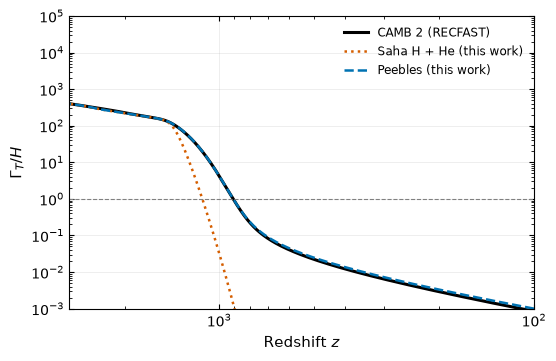

In [5]:
for name, f in [("Saha H+He", saha_xe), ("Peebles", peebles.x_e), ("CAMB", ref.x_e)]:
    print(f"{name:10s}: Gamma_T = H at z = {decoupling_redshift(f, cosmo):.1f}")

fig, ax = plt.subplots(figsize=(6, 3.8))
for key, f in [("camb", ref.x_e), ("saha_full", saha_xe), ("peebles", peebles.x_e)]:
    ax.plot(z, thomson_rate(z, f(z), cosmo) / cosmo.hubble(z), **STYLES[key])
ax.axhline(1, color="grey", ls="--", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=(3000, 100), ylim=(1e-3, 1e5),
       xlabel="Redshift $z$", ylabel="$\\Gamma_T/H$")
ax.legend();

## 4. Optical depth and the visibility function

$$\tau(z) = \int_0^z \frac{n_e(z')\,\sigma_T\,c}{(1+z')H(z')}\,dz', \qquad g(z) = \frac{d\tau}{dz}\,e^{-\tau(z)}.$$

$g(z)\,dz$ is the probability that a CMB photon last scattered between $z$ and $z+dz$, and
$\int_0^\infty g\,dz = 1 - e^{-\tau(\infty)} \approx 1$. Planck defines $z_*$ by $\tau(z_*) = 1$.

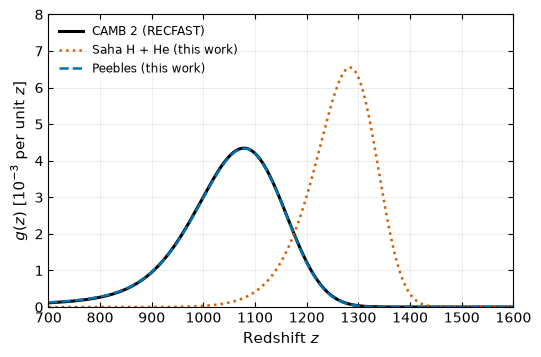

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for key, f in [("camb", ref.x_e), ("saha_full", saha_xe), ("peebles", peebles.x_e)]:
    ls = last_scattering(f, cosmo)
    ax.plot(ls.z, 1e3 * ls.g, **STYLES[key])
ax.set(xlim=(700, 1600), ylim=(0, 8), xlabel="Redshift $z$", ylabel="$g(z)$ [$10^{-3}$ per unit $z$]")
ax.legend();

## 5. Summary of results

The peak of $g(z)$ *per unit redshift* sits about 10 below $z_*$. The visibility per unit conformal time,
$g_\eta \propto g(z)\,H(z)$, peaks close to $z_*$. All three are reported to make the convention explicit.

In [7]:
rows = {"Peebles": key_results(peebles.x_e, cosmo),
        "Peebles F=1.14": key_results(peebles_fudge.x_e, cosmo),
        "CAMB": key_results(ref.x_e, cosmo)}
fields = ["z_decoupling", "z_tau_one", "z_peak", "z_peak_conformal", "fwhm", "x_e_freeze_out", "x_e_today"]
print(f"{'quantity':18s}" + "".join(f"{k:>16s}" for k in rows))
for fld in fields:
    vals = [getattr(r, fld) for r in rows.values()]
    fmt = "{:16.3e}" if fld.startswith("x_e") else "{:16.2f}"
    print(f"{fld:18s}" + "".join(fmt.format(v) for v in vals))
print(f"\nCAMB internal z_* = {ref.z_star:.3f}")

quantity                   Peebles  Peebles F=1.14            CAMB
z_decoupling                903.18          904.44          903.55
z_tau_one                  1089.44         1090.28         1089.89
z_peak                     1078.80         1079.05         1078.37
z_peak_conformal           1089.11         1089.32         1088.78
fwhm                        203.33          202.73          204.00
x_e_freeze_out           3.849e-04       3.404e-04       3.375e-04
x_e_today                2.665e-04       2.351e-04       1.738e-04

CAMB internal z_* = 1089.892


## Limitations

* Three-level atom: no multi-level atom, no Lyman-series feedback, no two-photon Raman corrections
  (Chluba & Thomas 2011; Ali-Haïmoud & Hirata 2011, HyRec).
* Helium in Saha equilibrium: He I recombination is delayed in reality (Switzer & Hirata 2008).
* $T_{\rm m} = T_\gamma$: there is no matter-temperature ODE, so the residual ionisation at $z \lesssim 200$ is
  over-estimated.
* No reionisation, so $\tau$ here is the optical depth to recombination only.